# Reproduction notebook: CIFAR-10 under 5M parameters

This notebook reads **actual recorded experiments** and runs only CPU parameter/synthetic-forward checks. It does not train models, load private competition images, or run competition inference. Obtain data and run the explicit README training commands to train your own models. Model weights are not included.

The saved outputs were generated by the documented sequential IPython harness (`scripts/execute_notebook.py`). Run All in Jupyter is also supported. The two official leaderboard columns are transcribed evidence, not recomputed test accuracies.

In [1]:
from pathlib import Path
import json, sys, os
ROOT = Path.cwd()
if not (ROOT / 'src/dlend').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/dlend').is_dir(), 'Open from repository root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.mplconfig'))
from IPython.display import display, HTML, Image
import torch
torch.set_num_threads(2)
historical = json.loads((ROOT / 'results/runs/base400/environment.json').read_text())
print('Historical training environment:')
print(json.dumps(historical, indent=2))
print('Current notebook Python:', sys.version.split()[0])
print('Current torch:', torch.__version__)
print('Notebook checks use CPU; GPU availability does not start training.')

Historical training environment:
{
  "python": "3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]",
  "platform": "Windows-11-10.0.26200-SP0",
  "torch": "2.7.1+cu128",
  "torchvision": "0.22.1+cu128",
  "numpy": "2.5.4",
  "cuda_runtime": "12.8",
  "cuda_available": true,
  "gpu": "NVIDIA GeForce RTX 5070 Ti"
}
Current notebook Python: 3.12.10
Current torch: 2.7.1+cu128
Notebook checks use CPU; GPU availability does not start training.


## Data and methods

50,000 labeled competition images were split into 45,000 training / 5,000 validation images with seed 42 and grouped exact duplicates. The 2,000 hidden test images were not used to train. No external pretrained weights or extra training dataset were used. Validation was reused for model selection and many experiments; it is not a pristine independent test.

The public-best branch is scratch400 → raw best396 → mild60 → SWA45–60 + flip. The selected-final branch is scratch300 → EMA285 → robust60 → SWA45–60 + flip. The observed unselected private maximum continues that SWA for50 epochs and selects EMA29 + flip. Total compute epochs differ from selected weight lineage.

In [2]:
from dlend.models import build_model, count_parameters
from dlend.train import resolve_config
torch.manual_seed(0)
architecture = []
for name in ['base400', 'robust300']:
    cfg = resolve_config(json.loads((ROOT / 'configs' / (name + '.json')).read_text()))
    model = build_model(cfg['model']).eval()
    with torch.inference_mode():
        output = model(torch.zeros(2, 3, 32, 32))
    assert output.shape == (2, 10) and torch.isfinite(output).all()
    count = count_parameters(model)
    assert count <= 5_000_000
    architecture.append({'family': name, 'parameters': count,
                         'blocks': list(model.stage_blocks), 'channels': list(model.stage_widths),
                         'kernels': list(model.kernel_sizes), 'output_shape': list(output.shape)})
print(json.dumps(architecture, indent=2))
print('Synthetic zeros verify shapes and finite outputs only; they are not accuracy evidence.')

[
  {
    "family": "base400",
    "parameters": 4480474,
    "blocks": [
      4,
      4,
      4
    ],
    "channels": [
      56,
      112,
      224
    ],
    "kernels": [
      3,
      3,
      3
    ],
    "output_shape": [
      2,
      10
    ]
  },
  {
    "family": "robust300",
    "parameters": 4948626,
    "blocks": [
      4,
      4,
      4
    ],
    "channels": [
      58,
      116,
      232
    ],
    "kernels": [
      3,
      3,
      3
    ],
    "output_shape": [
      2,
      10
    ]
  }
]
Synthetic zeros verify shapes and finite outputs only; they are not accuracy evidence.


## Actual results, with distinct identities

The selected final private score is **86.3%**. The visible unselected maximum87.3% must not be substituted for it. Public-best89.4% is yet another result. Official values come from the user's submission screenshot, filename-matched to local records; uploaded bytes were not independently retrieved.

In [3]:
records = json.loads((ROOT / 'results/key_results.json').read_text())
rows = []
for item in records['models']:
    rows.append('<tr>' + ''.join('<td>' + str(x) + '</td>' for x in [
        item['id'], item['role'], f"{item['parameters']:,}",
        f"{100*item['validation_fp32_cpu']['flip']:.2f}%",
        f"{100*item['public_accuracy']:.1f}%", f"{100*item['private_accuracy']:.1f}%"] ) + '</tr>')
display(HTML('<table><thead><tr>' + ''.join('<th>'+x+'</th>' for x in
    ['Run','Role','Parameters','Validation FP32 + flip','Public','Private']) +
    '</tr></thead><tbody>' + ''.join(rows) + '</tbody></table>'))
print('Validation sample count:', records['models'][0]['validation_count'])
print('All values above are saved historical results, not a new evaluation.')

Validation sample count: 5000
All values above are saved historical results, not a new evaluation.


Run,Role,Parameters,Validation FP32 + flip,Public,Private
mild60,public_best_selected,"4,480,474",97.36%,89.4%,86.1%
robust60,selected_final,"4,948,626",97.40%,88.6%,86.3%
robust_refine50,highest_private_visible_not_selected,"4,948,626",97.48%,88.6%,87.3%


## Complete training curves

All400+60+300+60+50=870 phase epochs appear below, without smoothing. Lines show historical CUDA BF16 single-view raw/EMA validation. CPU FP32+flip and recalibrated SWA are separately evaluated endpoints, not points on these curves. Mixed-target training loss differs from clean validation NLL; `train_acc` is soft-target agreement and is deliberately not presented as ordinary training accuracy.

Rendered complete real logs for five reproduction phases.


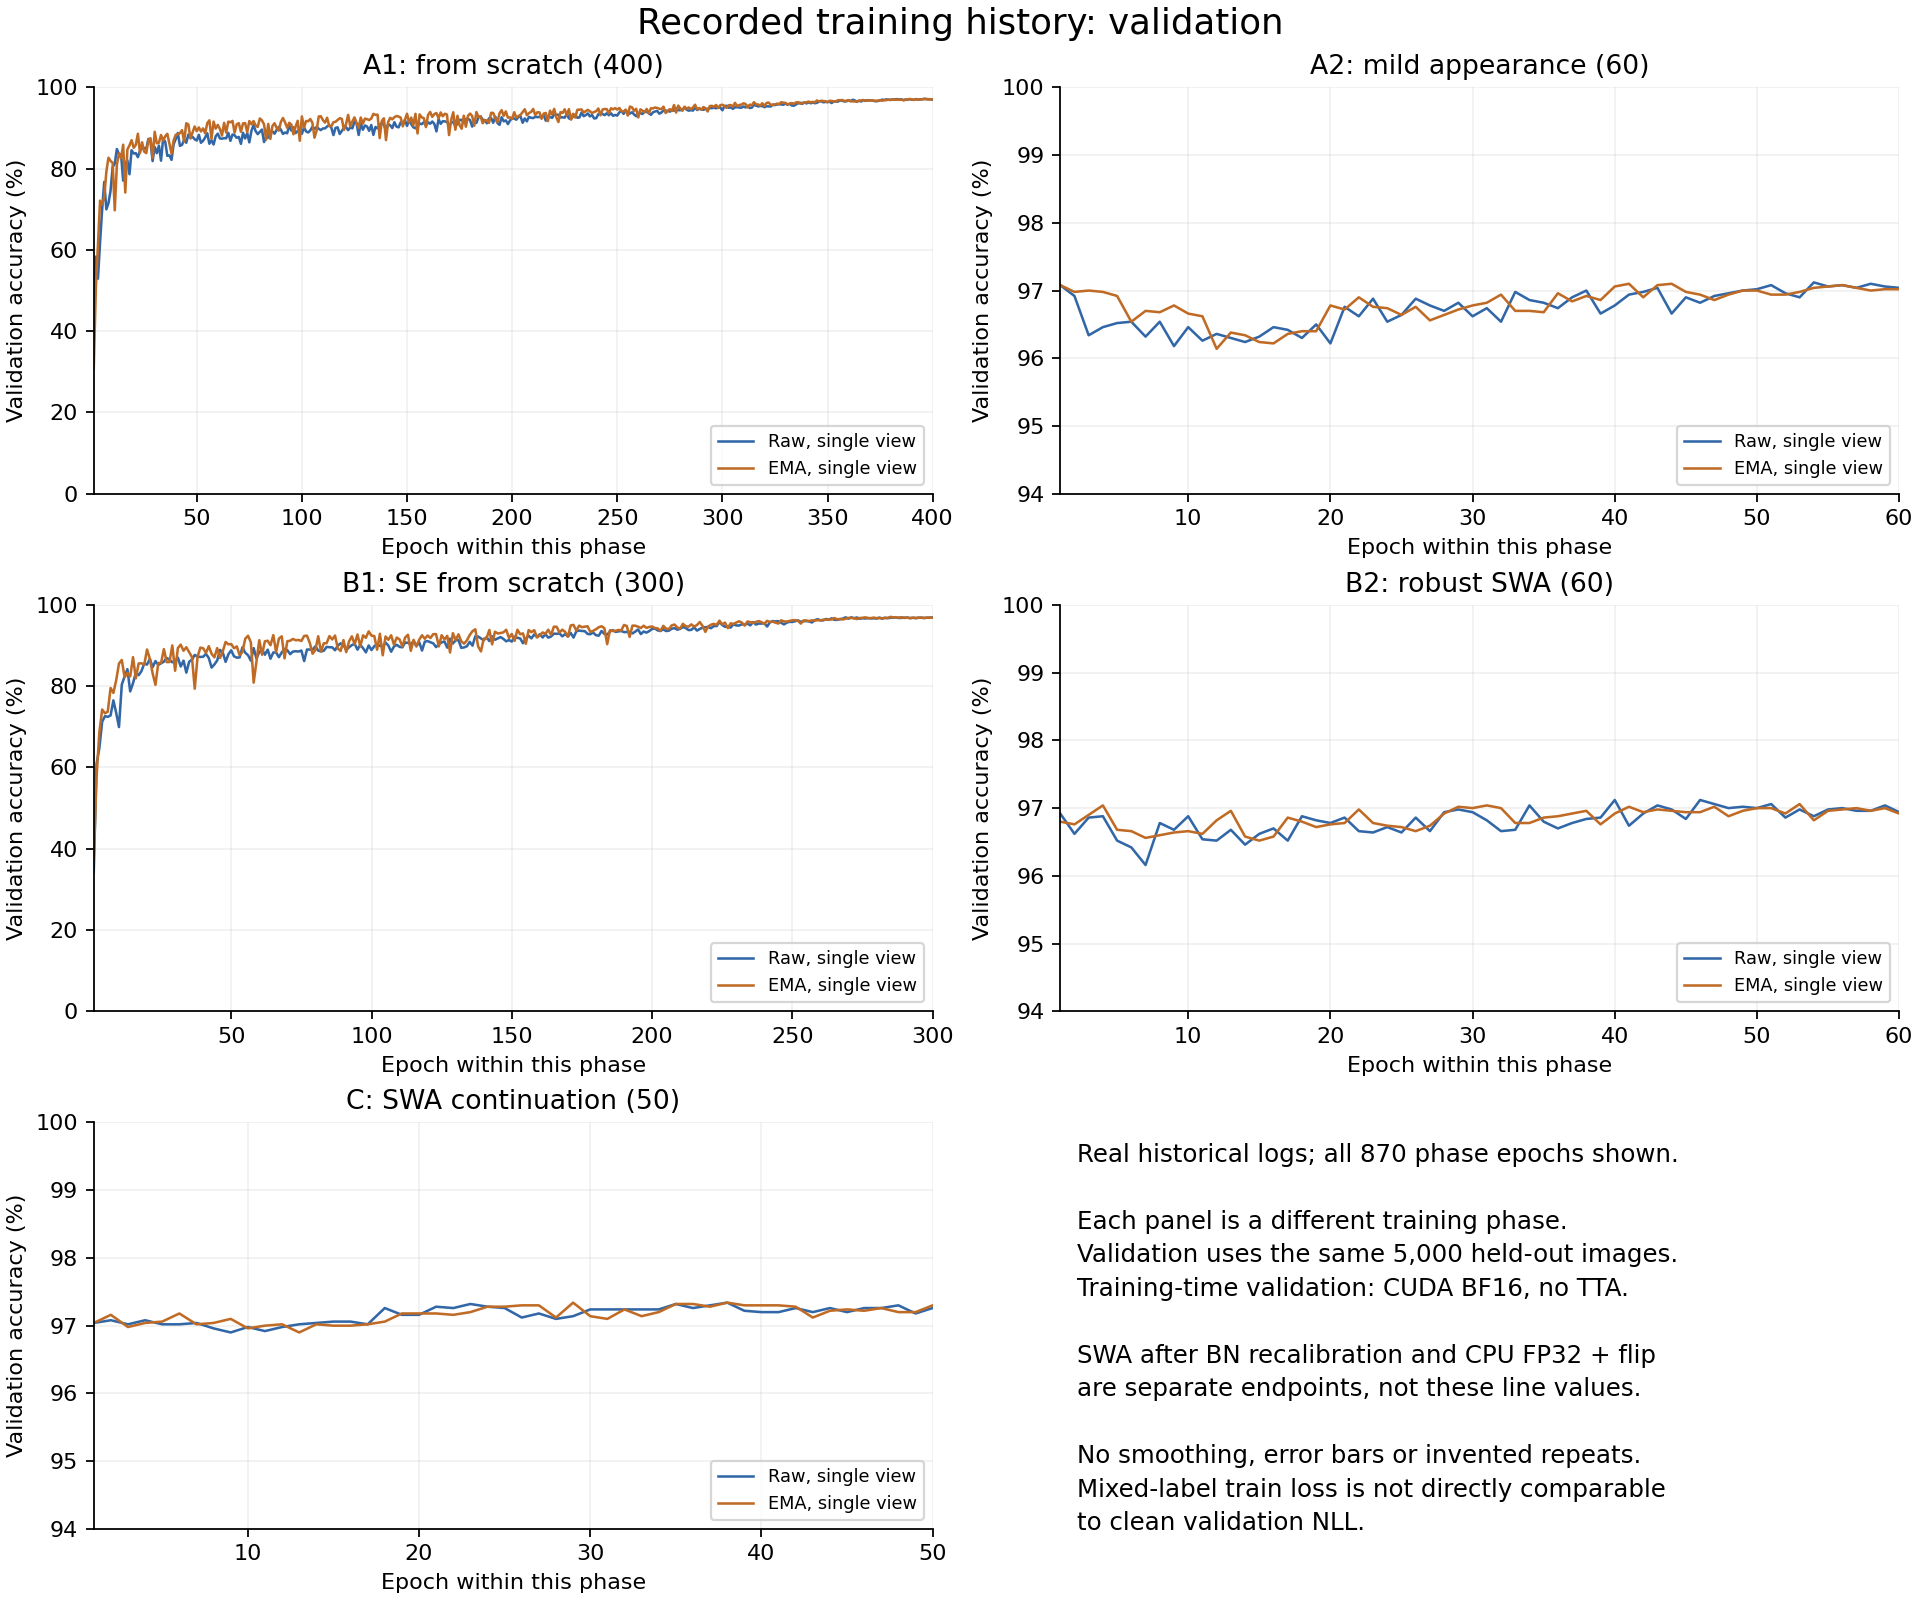

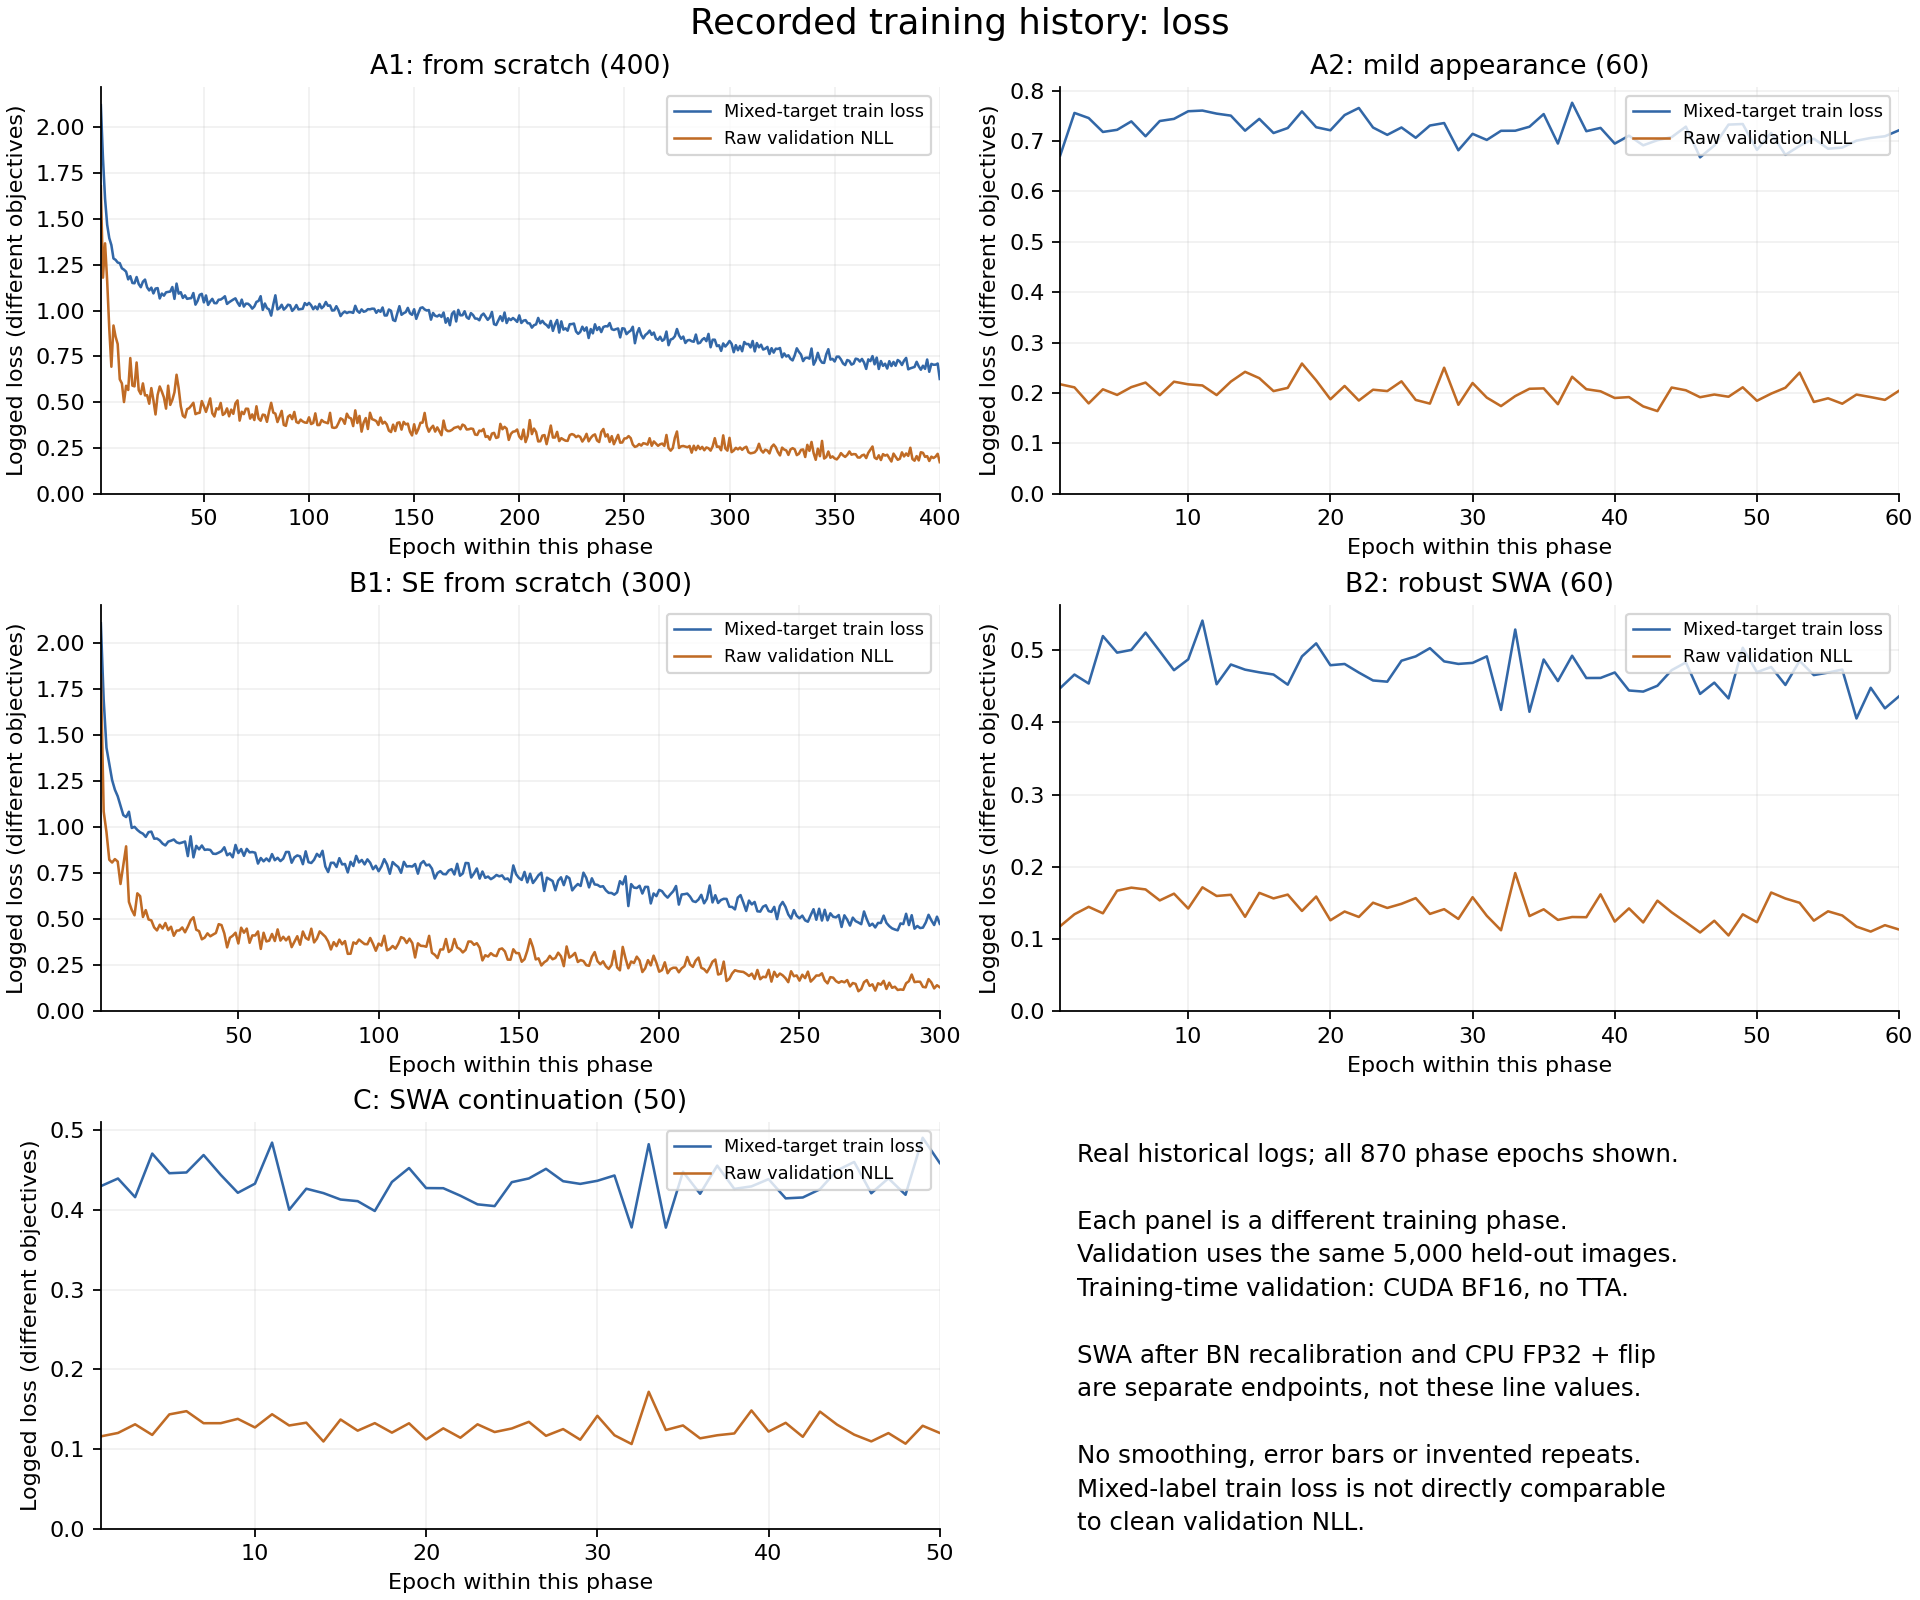

In [4]:
from plot_training_curves import render
paths = render()
for path in paths:
    display(Image(filename=str(path)))
print('Rendered complete real logs for five reproduction phases.')

## Experiment coverage and limitations

The aggregate ledger contains the finite historical exploration, including architecture allocations, width/kernel/shortcut/pool choices, optimizers, schedules, augmentations, regularization, distillation, quantization and isolated follow-ups. It is not proof that every possible combination was tried or that every method improved accuracy. The directly verified reproduction routes focus on the three submissions above. The archive also supplies all79 complete configurations, aggregate logs and corresponding source snapshots; all79 training commands have not been re-executed in this package, and private historical authorization files are excluded.

The original trained checkpoint bytes are not distributed here. Reruns may select different epochs and give different scores because training used nondeterministic CUDA settings. Dataset paths are the only changed configuration values. The portable SWA admission layer is explicitly documented; the underlying original training loop is preserved.

In [5]:
ledger = json.loads((ROOT / 'results/experiment_ledger.json').read_text(encoding='utf-8'))
print('Full historical ledger is present:', len((ROOT / 'results/experiment_ledger.json').read_bytes()), 'bytes')
print('Ledger top-level fields:', ', '.join(ledger))
manifest = json.loads((ROOT / 'provenance/source_mapping.json').read_text())
import hashlib
for item in manifest['exact_copies']:
    assert hashlib.sha256((ROOT / item['published_path']).read_bytes()).hexdigest() == item['published_sha256']
assert all(item['all_other_values_equal'] for item in manifest['configuration_mapping'])
print('Passed exact source/log hash checks:', len(manifest['exact_copies']))
print('Portable configs: dataset.root changed; all other values preserved.')
print('No training or competition-image inference was launched.')

Full historical ledger is present: 252600 bytes
Ledger top-level fields: status, counting_definition, totals, historical_count_reconciliation, queue_totals, coverage, observed_config_values, run_ledger, representative_cpu_fp32_results, latest_controlled_results, quantization, not_claimed, official_scores_scope, source_evidence_sha256
Passed exact source/log hash checks: 30
Portable configs: dataset.root changed; all other values preserved.
No training or competition-image inference was launched.
